In [1]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Keep the notebook reproducible
DATA_PATH = Path("data") / "netflix_titles_cleaned.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Unique titles IDs:", df["show_id"].nunique())
print("Duplicate IDs:", df["show_id"].duplicated().sum())

df.head()


Dataset loaded successfully
Shape: (8807, 15)
Columns: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description', 'date_added_parsed', 'duration_minutes', 'duration_seasons']
Unique titles IDs: 8807
Duplicate IDs: 0


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,date_added_parsed,duration_minutes,duration_seasons
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021-09-25,90.0,NaN
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021-09-24,NaN,2.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021-09-24,NaN,1.0
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021-09-24,NaN,1.0
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021-09-24,NaN,2.0


In [2]:

# Task 3.3: Content type distribution

content_counts = df["type"].value_counts()

content_distribution = pd.DataFrame({
    "content_type": content_counts.index,
    "count": content_counts.values,
    "percentage": (
        content_counts.values / len(df) * 100
    ).round(2)
})

print(content_distribution.to_string(index=False))
print("\nTotal records:", content_counts.sum())
print("Total percentage:", content_distribution["percentage"].sum())


content_type  count  percentage
       Movie   6131       69.62
     TV Show   2676       30.38

Total records: 8807
Total percentage: 100.0


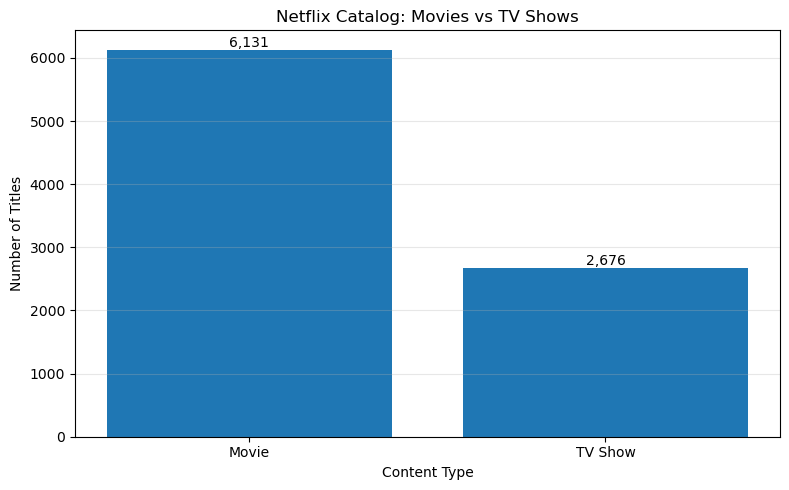

In [3]:

# Netflix Movies vs TV Shows — bar chart

plt.figure(figsize=(8, 5))

bars = plt.bar(
    content_distribution["content_type"],
    content_distribution["count"]
)

plt.title("Netflix Catalog: Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

# Save as a scalable vector graphic
plt.savefig(
    "content_distribution.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [4]:

# Task 3.4: Titles added per year

df["date_added_parsed"] = pd.to_datetime(
    df["date_added_parsed"],
    errors="coerce"
)

df["year_added"] = df["date_added_parsed"].dt.year

yearly_additions = (
    df["year_added"]
    .value_counts()
    .sort_index()
)

print("Titles added per year:")
print(yearly_additions.to_string())

print("\nTotal titles with a valid date:", yearly_additions.sum())
print("Years covered:", yearly_additions.index.min(), "to", yearly_additions.index.max())
print("Year with most additions:", yearly_additions.idxmax())
print("Maximum additions in one year:", yearly_additions.max())


Titles added per year:
year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498

Total titles with a valid date: 8797
Years covered: 2008.0 to 2021.0
Year with most additions: 2019.0
Maximum additions in one year: 2016


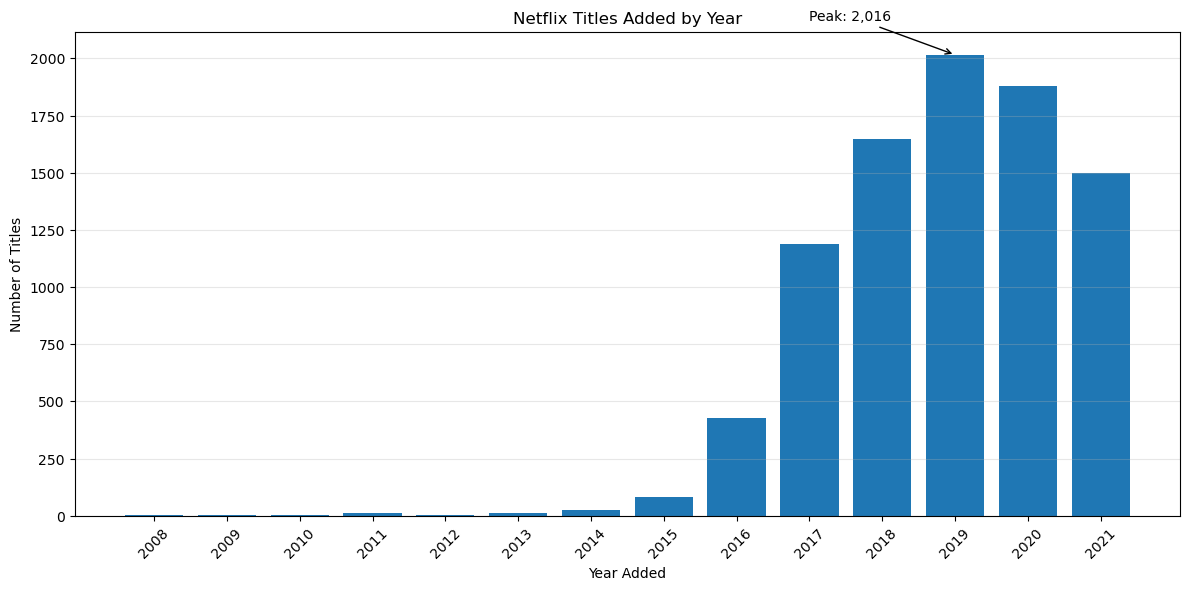

In [5]:

# Netflix titles added by year

plt.figure(figsize=(12, 6))

bars = plt.bar(
    yearly_additions.index.astype(int),
    yearly_additions.values
)

plt.title("Netflix Titles Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.xticks(yearly_additions.index.astype(int), rotation=45)
plt.grid(axis="y", alpha=0.3)

# Label the peak year
peak_year = int(yearly_additions.idxmax())
peak_count = int(yearly_additions.max())

plt.annotate(
    f"Peak: {peak_count:,}",
    xy=(peak_year, peak_count),
    xytext=(peak_year - 2, peak_count + 150),
    arrowprops=dict(arrowstyle="->")
)

plt.tight_layout()

plt.savefig(
    "titles_added_by_year.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [6]:

# Task 3.5: Titles by original release year

release_year_counts = (
    df["release_year"]
    .value_counts()
    .sort_index()
)

print("Total titles:", len(df))
print("Titles with valid release years:", df["release_year"].notna().sum())
print("Earliest release year:", df["release_year"].min())
print("Latest release year:", df["release_year"].max())

print("\nTop 10 release years by title count:")
print(
    df["release_year"]
    .value_counts()
    .head(10)
    .rename_axis("release_year")
    .reset_index(name="title_count")
    .to_string(index=False)
)


Total titles: 8807
Titles with valid release years: 8807
Earliest release year: 1925
Latest release year: 2021

Top 10 release years by title count:
 release_year  title_count
         2018         1147
         2017         1032
         2019         1030
         2020          953
         2016          902
         2021          592
         2015          560
         2014          352
         2013          288
         2012          237


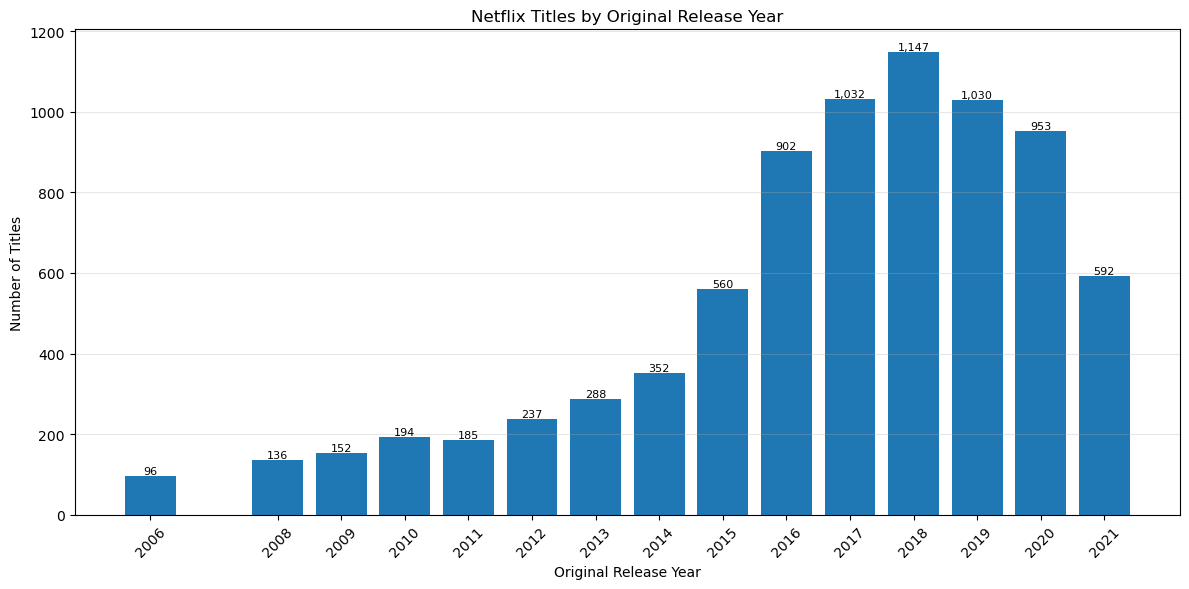

In [7]:

# Top 15 release years by number of titles

top_release_years = (
    df["release_year"]
    .value_counts()
    .head(15)
    .sort_index()
)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    top_release_years.index.astype(int),
    top_release_years.values
)

plt.title("Netflix Titles by Original Release Year")
plt.xlabel("Original Release Year")
plt.ylabel("Number of Titles")
plt.xticks(top_release_years.index.astype(int), rotation=45)
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()

plt.savefig(
    "titles_by_release_year.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()



In [8]:

# Task 3.6: Content rating distribution

rating_counts = df["rating"].value_counts()

rating_distribution = pd.DataFrame({
    "rating": rating_counts.index,
    "title_count": rating_counts.values,
    "percentage_of_all_titles": (
        rating_counts.values / len(df) * 100
    ).round(2)
})

print("Total titles:", len(df))
print("Titles with missing ratings:", df["rating"].isna().sum())
print("Titles with known ratings:", df["rating"].notna().sum())

print("\nTop 10 ratings:")
print(rating_distribution.head(10).to_string(index=False))

print(
    "\nKnown-rating total:",
    rating_distribution["title_count"].sum()
)


Total titles: 8807
Titles with missing ratings: 7
Titles with known ratings: 8800

Top 10 ratings:
rating  title_count  percentage_of_all_titles
 TV-MA         3207                     36.41
 TV-14         2160                     24.53
 TV-PG          863                      9.80
     R          799                      9.07
 PG-13          490                      5.56
 TV-Y7          334                      3.79
  TV-Y          307                      3.49
    PG          287                      3.26
  TV-G          220                      2.50
    NR           80                      0.91

Known-rating total: 8800


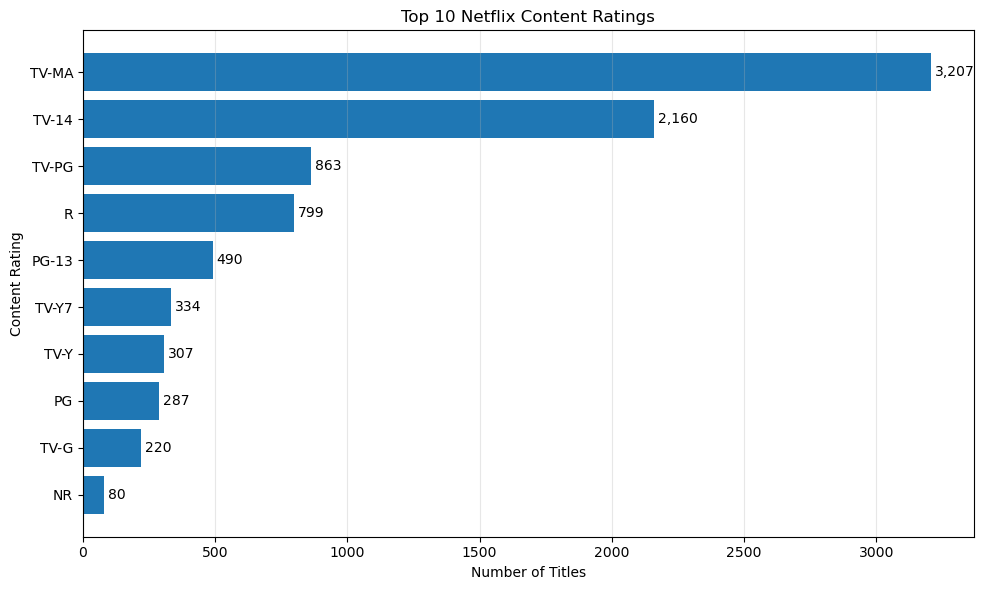

In [11]:

# Top 10 Netflix content ratings

top_ratings = df["rating"].value_counts().head(10).sort_values()

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_ratings.index,
    top_ratings.values
)

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.grid(axis="x", alpha=0.3)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 15,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    "content_rating_distribution.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [12]:

# Task 3.7: Analyze listed genres

genre_series = (
    df["listed_in"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

genre_counts = genre_series.value_counts()

print("Total genre assignments:", len(genre_series))
print("Unique genres:", genre_series.nunique())

print("\nTop 15 genres:")
print(
    genre_counts.head(15)
    .rename_axis("genre")
    .reset_index(name="title_count")
    .to_string(index=False)
)


Total genre assignments: 19323
Unique genres: 42

Top 15 genres:
                   genre  title_count
    International Movies         2752
                  Dramas         2427
                Comedies         1674
  International TV Shows         1351
           Documentaries          869
      Action & Adventure          859
               TV Dramas          763
      Independent Movies          756
Children & Family Movies          641
         Romantic Movies          616
             TV Comedies          581
               Thrillers          577
          Crime TV Shows          470
                Kids' TV          451
              Docuseries          395


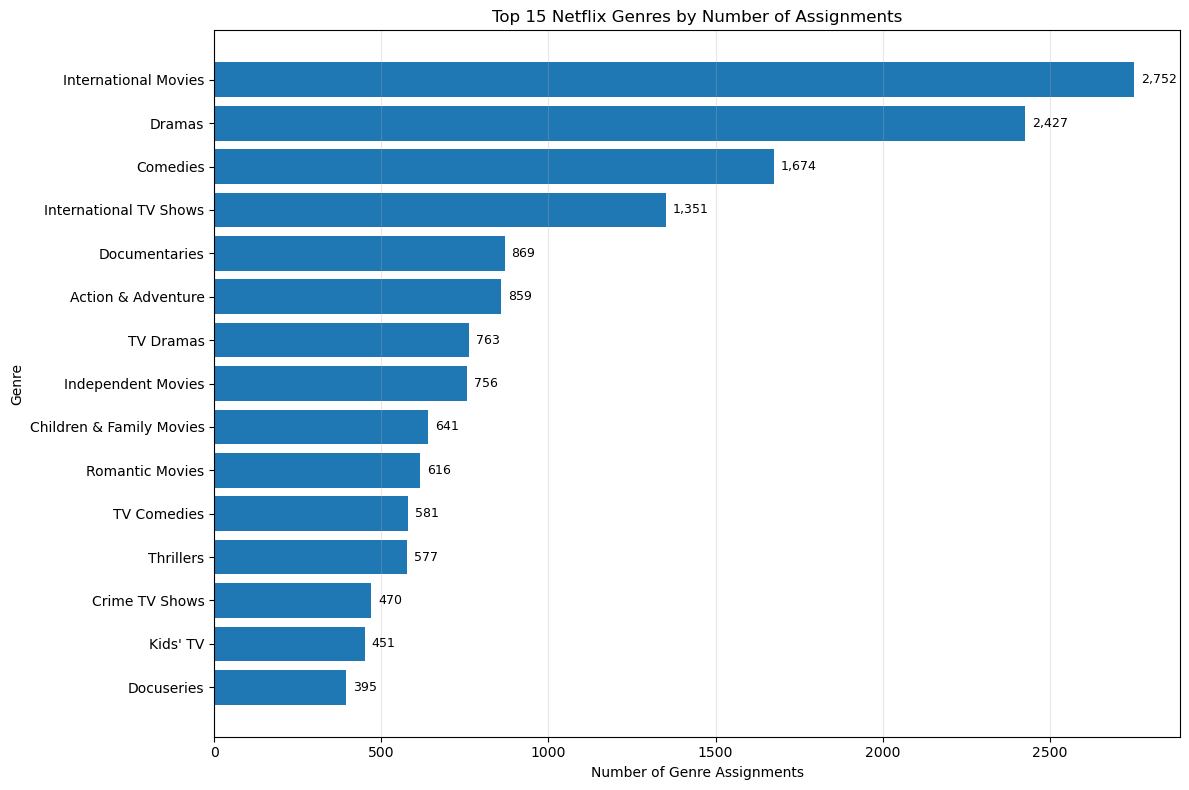

In [13]:

# Top 15 Netflix genres

top_genres = genre_counts.head(15).sort_values()

plt.figure(figsize=(12, 8))

bars = plt.barh(
    top_genres.index,
    top_genres.values
)

plt.title("Top 15 Netflix Genres by Number of Assignments")
plt.xlabel("Number of Genre Assignments")
plt.ylabel("Genre")
plt.grid(axis="x", alpha=0.3)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 20,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "top_15_netflix_genres.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [14]:

# Task 3.8: Movie duration statistics

movie_durations = df.loc[
    df["type"].eq("Movie"),
    "duration_minutes"
].dropna()

print("Movies with valid numeric durations:", len(movie_durations))
print("Mean duration:", round(movie_durations.mean(), 2), "minutes")
print("Median duration:", movie_durations.median(), "minutes")
print("Minimum duration:", movie_durations.min(), "minutes")
print("Maximum duration:", movie_durations.max(), "minutes")

print("\nDuration quartiles:")
print(movie_durations.quantile([0.25, 0.50, 0.75]).to_string())

print("\nDescriptive statistics:")
print(movie_durations.describe().round(2).to_string())


Movies with valid numeric durations: 6131
Mean duration: 99.56 minutes
Median duration: 98.0 minutes
Minimum duration: 3.0 minutes
Maximum duration: 312.0 minutes

Duration quartiles:
0.25     87.0
0.50     98.0
0.75    114.0

Descriptive statistics:
count    6131.00
mean       99.56
std        28.29
min         3.00
25%        87.00
50%        98.00
75%       114.00
max       312.00


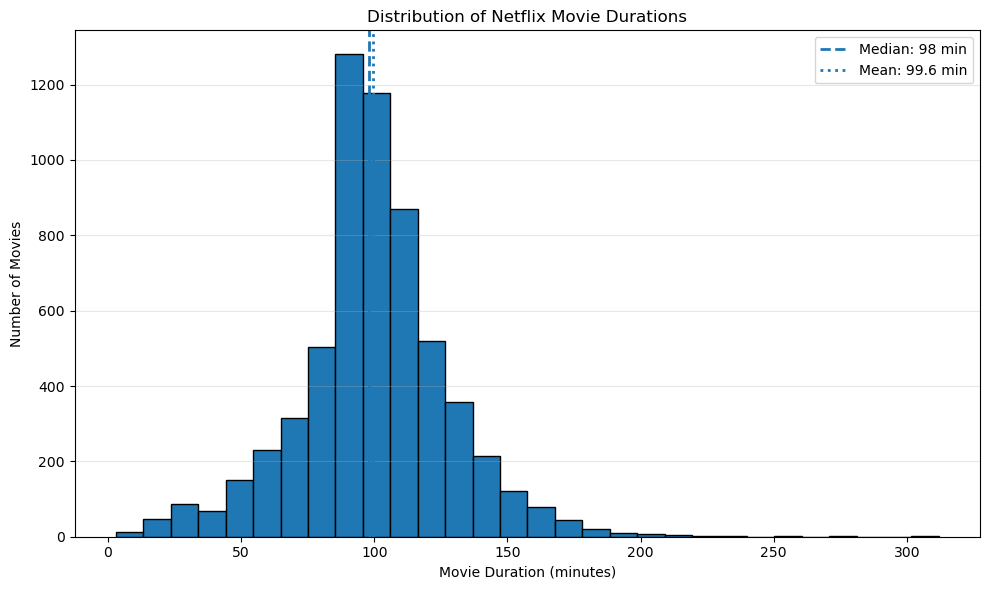

In [15]:

# Distribution of Netflix movie durations

plt.figure(figsize=(10, 6))

plt.hist(
    movie_durations,
    bins=30,
    edgecolor="black"
)

plt.axvline(
    movie_durations.median(),
    linestyle="--",
    linewidth=2,
    label=f"Median: {movie_durations.median():.0f} min"
)

plt.axvline(
    movie_durations.mean(),
    linestyle=":",
    linewidth=2,
    label=f"Mean: {movie_durations.mean():.1f} min"
)

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Movie Duration (minutes)")
plt.ylabel("Number of Movies")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "movie_duration_distribution.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [16]:

# Task 3.9: TV Show season statistics

tv_seasons = df.loc[
    df["type"].eq("TV Show"),
    "duration_seasons"
].dropna()

print("TV Shows with valid season counts:", len(tv_seasons))
print("Mean seasons:", round(tv_seasons.mean(), 2))
print("Median seasons:", tv_seasons.median())
print("Minimum seasons:", tv_seasons.min())
print("Maximum seasons:", tv_seasons.max())

print("\nSeason count distribution:")
print(
    tv_seasons.value_counts()
    .sort_index()
    .rename_axis("seasons")
    .reset_index(name="show_count")
    .to_string(index=False)
)

print("\nDescriptive statistics:")
print(tv_seasons.describe().round(2).to_string())


TV Shows with valid season counts: 2676
Mean seasons: 1.76
Median seasons: 1.0
Minimum seasons: 1.0
Maximum seasons: 17.0

Season count distribution:
 seasons  show_count
     1.0        1793
     2.0         425
     3.0         199
     4.0          95
     5.0          65
     6.0          33
     7.0          23
     8.0          17
     9.0           9
    10.0           7
    11.0           2
    12.0           2
    13.0           3
    15.0           2
    17.0           1

Descriptive statistics:
count    2676.00
mean        1.76
std         1.58
min         1.00
25%         1.00
50%         1.00
75%         2.00
max        17.00


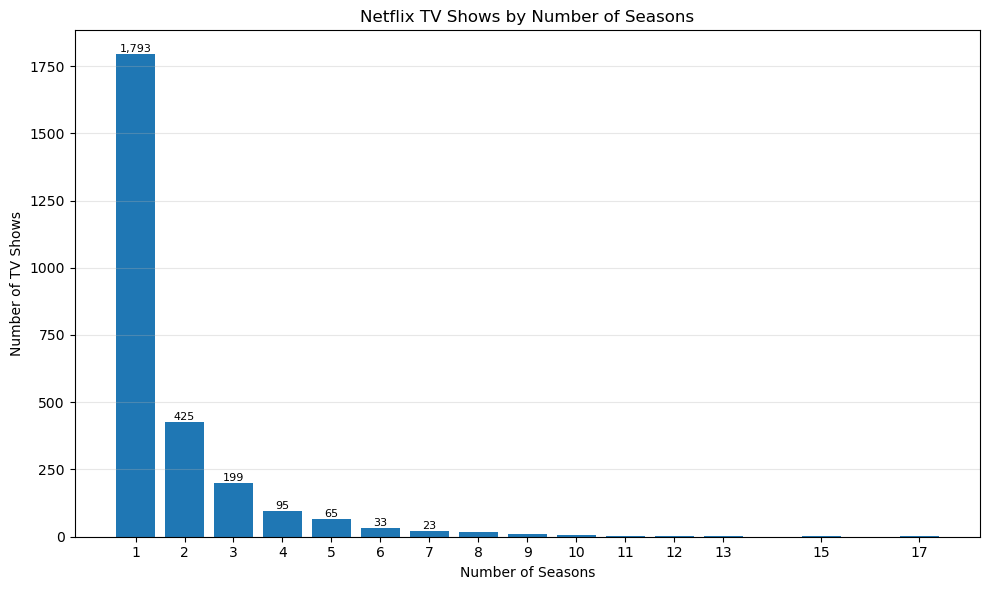

In [17]:

# Distribution of Netflix TV Show season counts

season_counts = tv_seasons.value_counts().sort_index()

plt.figure(figsize=(10, 6))

bars = plt.bar(
    season_counts.index.astype(int),
    season_counts.values
)

plt.title("Netflix TV Shows by Number of Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")
plt.xticks(season_counts.index.astype(int))
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    if height >= 20:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height):,}",
            ha="center",
            va="bottom",
            fontsize=8
        )

plt.tight_layout()

plt.savefig(
    "tv_show_season_distribution.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()



In [18]:

# Task 3.10: Country analysis

country_series = (
    df["country"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

country_counts = country_series.value_counts()

print("Titles with a non-missing country field:", df["country"].notna().sum())
print("Total country assignments:", len(country_series))
print("Unique countries:", country_series.nunique())

print("\nTop 15 countries:")
print(
    country_counts.head(15)
    .rename_axis("country")
    .reset_index(name="country_assignments")
    .to_string(index=False)
)


Titles with a non-missing country field: 7976
Total country assignments: 10019
Unique countries: 123

Top 15 countries:
       country  country_assignments
 United States                 3690
         India                 1046
United Kingdom                  806
        Canada                  445
        France                  393
         Japan                  318
         Spain                  232
   South Korea                  231
       Germany                  226
        Mexico                  169
         China                  162
     Australia                  160
         Egypt                  117
        Turkey                  113
     Hong Kong                  105


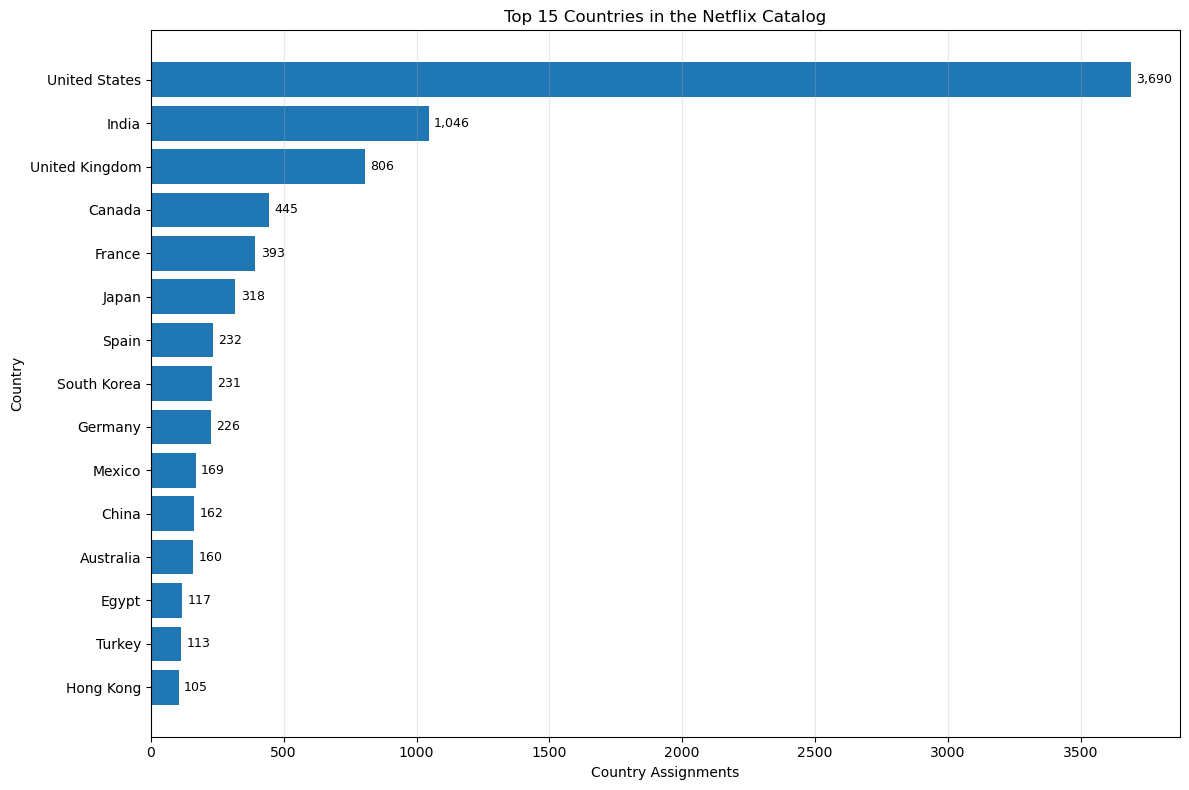

In [19]:

# Top 15 countries by Netflix catalog country assignments

top_countries = country_counts.head(15).sort_values()

plt.figure(figsize=(12, 8))

bars = plt.barh(
    top_countries.index,
    top_countries.values
)

plt.title("Top 15 Countries in the Netflix Catalog")
plt.xlabel("Country Assignments")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.3)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 20,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "top_15_countries.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()



In [20]:


# Task 3.11: Country-wise comparison of Movies and TV Shows

country_type_df = df[
    ["show_id", "type", "country"]
].dropna(subset=["country"]).copy()

country_type_df["country"] = (
    country_type_df["country"].str.split(",")
)

country_type_df = country_type_df.explode("country")

country_type_df["country"] = (
    country_type_df["country"].str.strip()
)

# Count titles by country and content type
country_type_counts = (
    country_type_df
    .groupby(["country", "type"])["show_id"]
    .nunique()
    .unstack(fill_value=0)
)

# Select the 10 leading countries from the previous analysis
top_10_countries = country_counts.head(10).index

comparison = (
    country_type_counts
    .reindex(top_10_countries)
    .fillna(0)
    .astype(int)
)

print("Top 10 countries — Movies vs TV Shows")
print(comparison.to_string())

print("\nGrand totals by content type within these country associations:")
print(comparison.sum().to_string())


Top 10 countries — Movies vs TV Shows
type            Movie  TV Show
country                       
United States    2752      938
India             962       84
United Kingdom    534      272
Canada            319      126
France            303       90
Japan             119      199
Spain             171       61
South Korea        61      170
Germany           182       44
Mexico            111       58

Grand totals by content type within these country associations:
type
Movie      5514
TV Show    2042


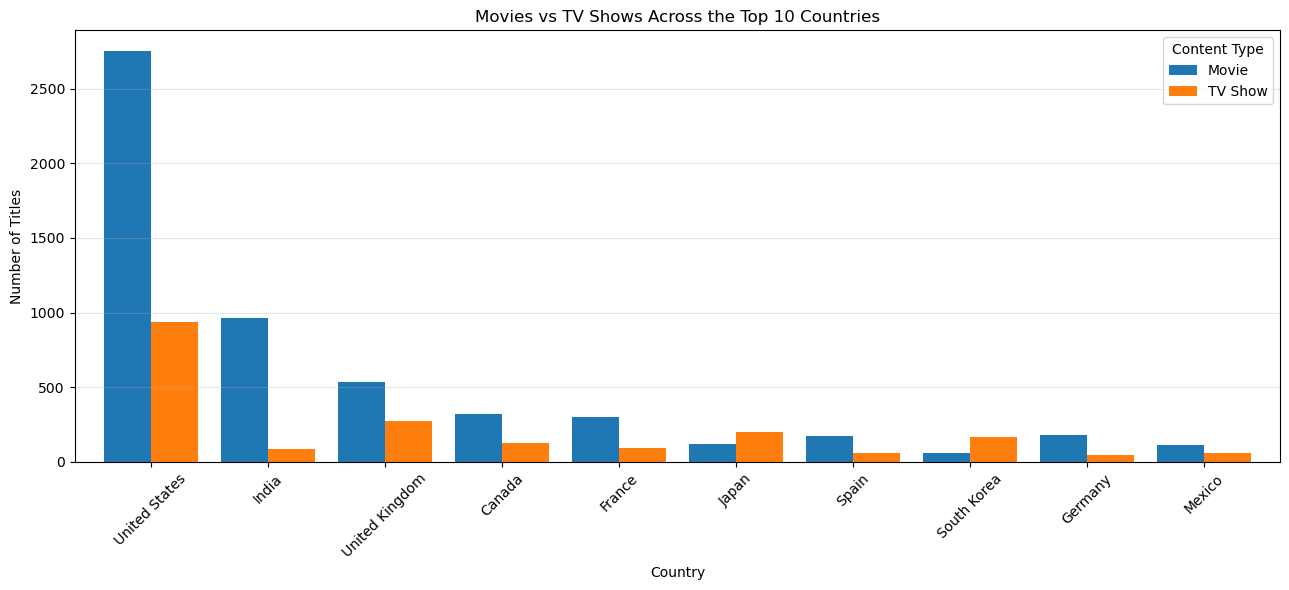

In [21]:


# Compare Movies and TV Shows across the top 10 countries

ax = comparison.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

ax.set_title("Movies vs TV Shows Across the Top 10 Countries")
ax.set_xlabel("Country")
ax.set_ylabel("Number of Titles")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Content Type")

plt.tight_layout()

plt.savefig(
    "country_movie_tv_comparison.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [22]:


# Task 3.12: Release year vs content type

release_type_counts = (
    df.groupby(["release_year", "type"])["show_id"]
    .nunique()
    .unstack(fill_value=0)
    .sort_index()
)

recent_release_type_counts = release_type_counts.tail(15)

print("Release years included:")
print(
    recent_release_type_counts.index.min(),
    "to",
    recent_release_type_counts.index.max()
)

print("\nMovies vs TV Shows by release year:")
print(recent_release_type_counts.to_string())

print("\nTotals for selected release years:")
print(recent_release_type_counts.sum().to_string())


Release years included:
2007 to 2021

Movies vs TV Shows by release year:
type          Movie  TV Show
release_year                
2007             74       14
2008            113       23
2009            118       34
2010            154       40
2011            145       40
2012            173       64
2013            225       63
2014            264       88
2015            398      162
2016            658      244
2017            767      265
2018            767      380
2019            633      397
2020            517      436
2021            277      315

Totals for selected release years:
type
Movie      5283
TV Show    2565


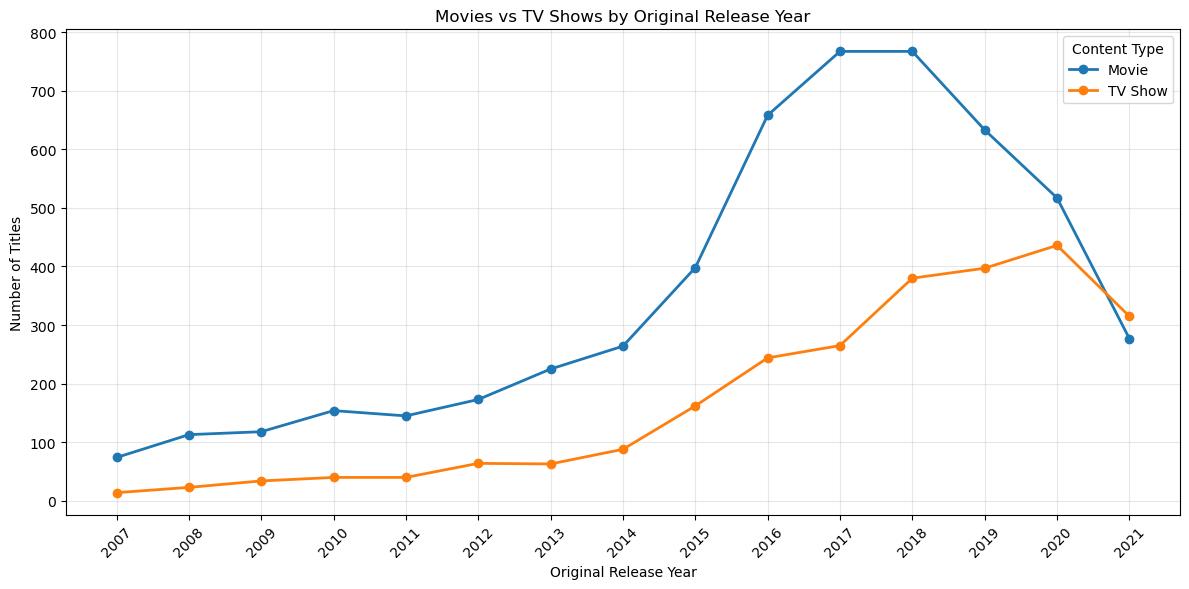

In [23]:


# Movies vs TV Shows by original release year

ax = recent_release_type_counts.plot(
    kind="line",
    marker="o",
    figsize=(12, 6),
    linewidth=2
)

ax.set_title("Movies vs TV Shows by Original Release Year")
ax.set_xlabel("Original Release Year")
ax.set_ylabel("Number of Titles")
ax.legend(title="Content Type")
ax.grid(alpha=0.3)

plt.xticks(recent_release_type_counts.index, rotation=45)
plt.tight_layout()

plt.savefig(
    "release_year_movie_tv_trend.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [24]:


# Task 3.13: Director analysis

director_series = (
    df["director"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

director_counts = director_series.value_counts()

print("Titles with director information:", df["director"].notna().sum())
print("Total director assignments:", len(director_series))
print("Unique director names:", director_series.nunique())

print("\nTop 15 directors:")
print(
    director_counts.head(15)
    .rename_axis("director")
    .reset_index(name="title_count")
    .to_string(index=False)
)


Titles with director information: 6173
Total director assignments: 6978
Unique director names: 4993

Top 15 directors:
           director  title_count
      Rajiv Chilaka           22
          Jan Suter           21
        Raúl Campos           19
       Marcus Raboy           16
        Suhas Kadav           16
          Jay Karas           15
Cathy Garcia-Molina           13
    Youssef Chahine           12
    Martin Scorsese           12
        Jay Chapman           12
   Steven Spielberg           11
   Don Michael Paul           10
       David Dhawan            9
     Yılmaz Erdoğan            9
    Shannon Hartman            9


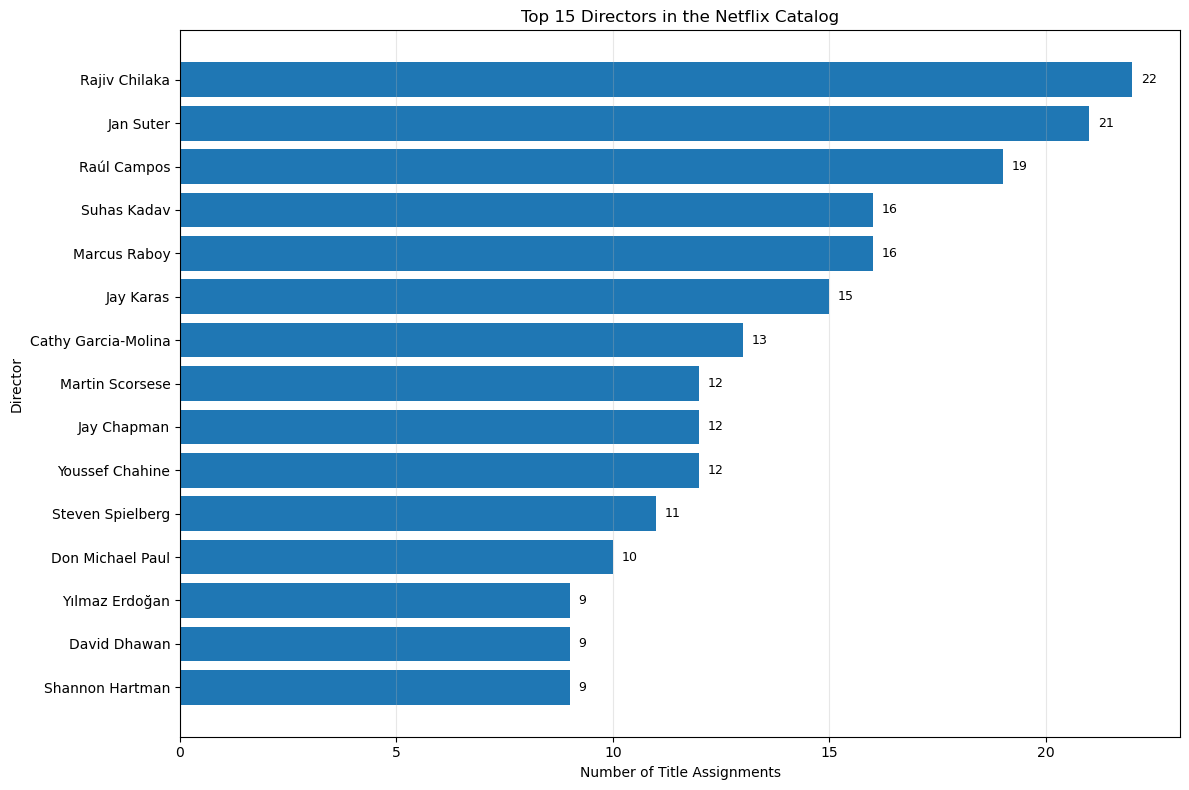

In [25]:


# Top 15 directors by title assignments

top_directors = director_counts.head(15).sort_values()

plt.figure(figsize=(12, 8))

bars = plt.barh(
    top_directors.index,
    top_directors.values
)

plt.title("Top 15 Directors in the Netflix Catalog")
plt.xlabel("Number of Title Assignments")
plt.ylabel("Director")
plt.grid(axis="x", alpha=0.3)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "top_15_directors.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [26]:


# Task 3.14: Cast analysis

cast_series = (
    df["cast"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

cast_counts = cast_series.value_counts()

print("Titles with cast information:", df["cast"].notna().sum())
print("Total cast assignments:", len(cast_series))
print("Unique performer names:", cast_series.nunique())

print("\nTop 15 performers by title appearances:")
print(
    cast_counts.head(15)
    .rename_axis("performer")
    .reset_index(name="title_appearances")
    .to_string(index=False)
)


Titles with cast information: 7982
Total cast assignments: 64126
Unique performer names: 36439

Top 15 performers by title appearances:
       performer  title_appearances
     Anupam Kher                 43
  Shah Rukh Khan                 35
   Julie Tejwani                 33
Takahiro Sakurai                 32
Naseeruddin Shah                 32
    Rupa Bhimani                 31
         Om Puri                 30
    Akshay Kumar                 30
       Yuki Kaji                 29
Amitabh Bachchan                 28
    Paresh Rawal                 28
     Boman Irani                 27
     Rajesh Kava                 26
    Vincent Tong                 26
   Andrea Libman                 25


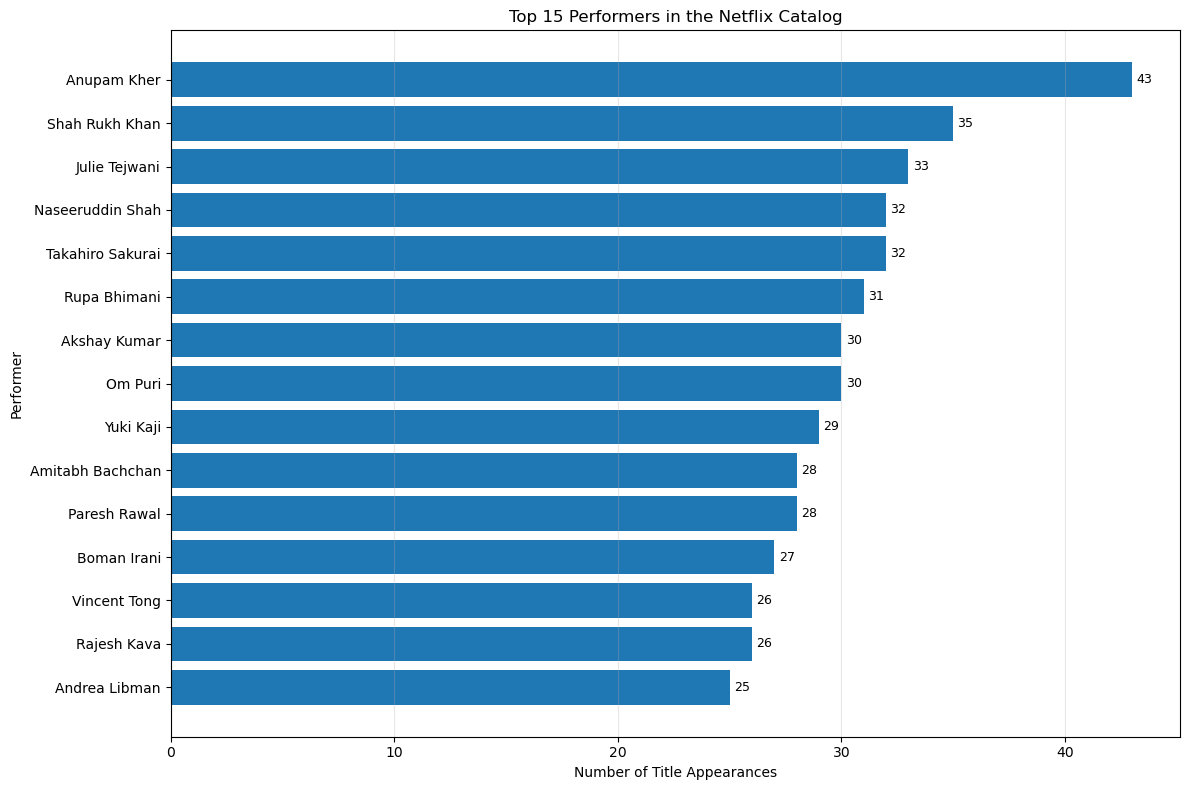

In [27]:

# Top 15 performers by Netflix catalog appearances

top_performers = cast_counts.head(15).sort_values()

plt.figure(figsize=(12, 8))

bars = plt.barh(
    top_performers.index,
    top_performers.values
)

plt.title("Top 15 Performers in the Netflix Catalog")
plt.xlabel("Number of Title Appearances")
plt.ylabel("Performer")
plt.grid(axis="x", alpha=0.3)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "top_15_performers.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [28]:


# Task 3.15: Content ratings by Movies vs TV Shows

rating_type_counts = pd.crosstab(
    df["rating"],
    df["type"]
)

print("Rating counts by content type:")
print(rating_type_counts.to_string())

print("\nTop 10 ratings overall, split by type:")
top_10_ratings = df["rating"].value_counts().head(10).index

print(
    rating_type_counts
    .reindex(top_10_ratings)
    .to_string()
)

print("\nMissing ratings by content type:")
print(
    df.groupby("type")["rating"]
    .apply(lambda x: x.isna().sum())
    .to_string()
)


Rating counts by content type:
type      Movie  TV Show
rating                  
G            41        0
NC-17         3        0
NR           75        5
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      733
TV-G        126       94
TV-MA      2062     1145
TV-PG       540      323
TV-Y        131      176
TV-Y7       139      195
TV-Y7-FV      5        1
UR            3        0

Top 10 ratings overall, split by type:
type    Movie  TV Show
rating                
TV-MA    2062     1145
TV-14    1427      733
TV-PG     540      323
R         797        2
PG-13     490        0
TV-Y7     139      195
TV-Y      131      176
PG        287        0
TV-G      126       94
NR         75        5

Missing ratings by content type:
type
Movie      5
TV Show    2


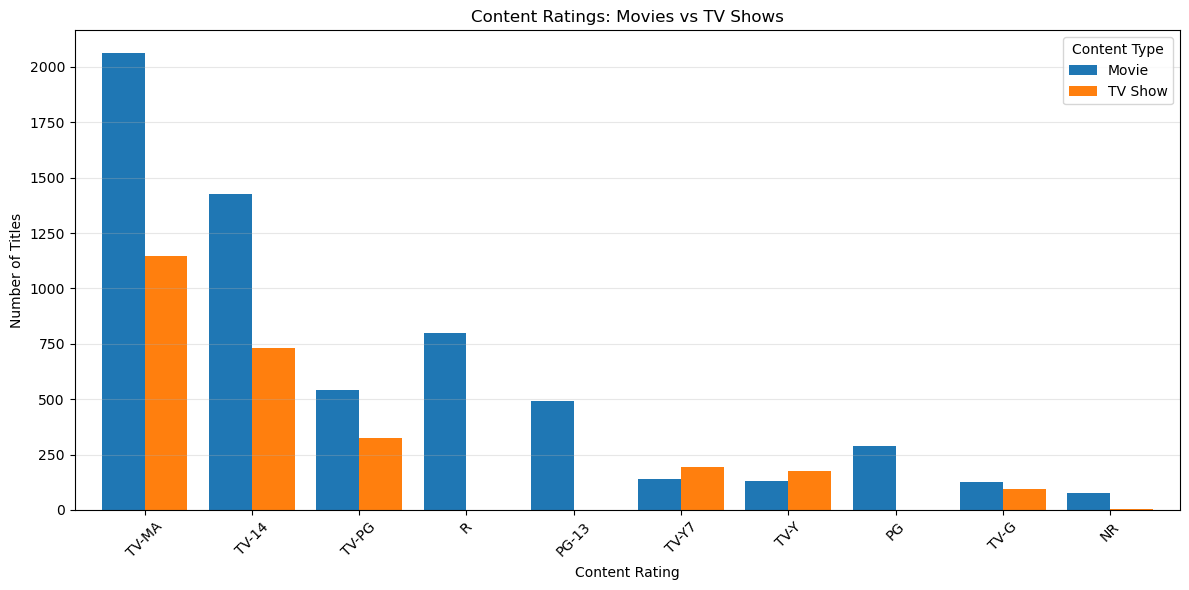

In [29]:


# Rating comparison: Movies vs TV Shows

top_ratings = df["rating"].value_counts().head(10).index

rating_comparison = (
    rating_type_counts
    .reindex(top_ratings)
    .fillna(0)
)

ax = rating_comparison.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Content Ratings: Movies vs TV Shows")
ax.set_xlabel("Content Rating")
ax.set_ylabel("Number of Titles")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Content Type")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "ratings_by_content_type.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [30]:


# Task 3.16: Monthly content additions

df["date_added_parsed"] = pd.to_datetime(
    df["date_added_parsed"],
    errors="coerce"
)

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

df["month_added"] = df["date_added_parsed"].dt.month

monthly_additions = (
    df["month_added"]
    .value_counts()
    .sort_index()
)

monthly_additions.index = monthly_additions.index.map(month_names)

print("Total titles with valid dates:", monthly_additions.sum())
print("\nTitles added by month:")
print(monthly_additions.to_string())

print("\nMonth with most additions:", monthly_additions.idxmax())
print("Maximum additions:", monthly_additions.max())


Total titles with valid dates: 8797

Titles added by month:
month_added
January      738
February     563
March        742
April        764
May          632
June         728
July         827
August       755
September    770
October      760
November     705
December     813

Month with most additions: July
Maximum additions: 827


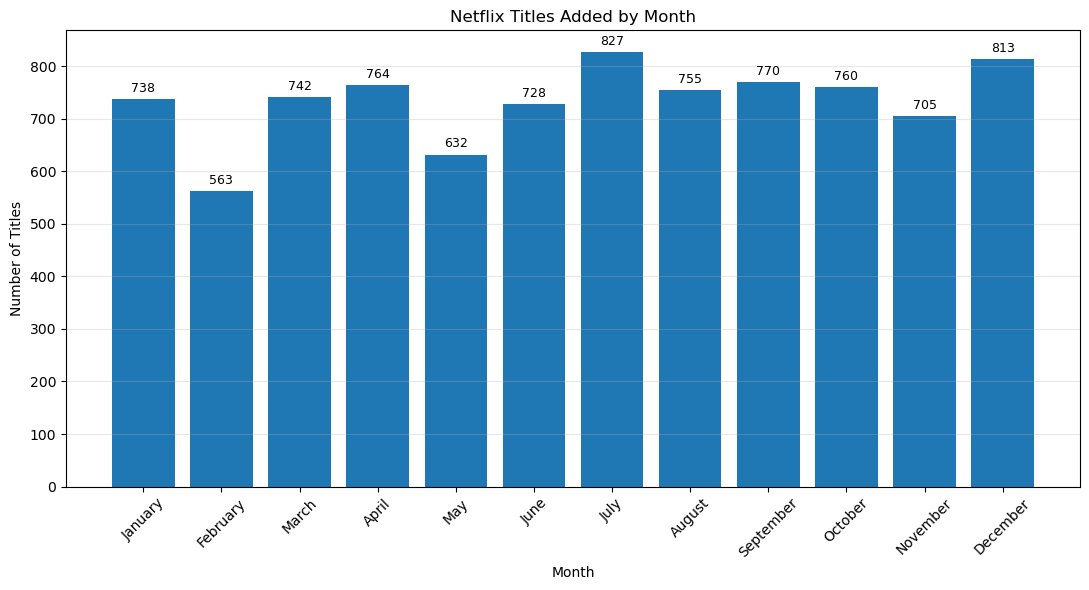

In [31]:


# Monthly Netflix additions

plt.figure(figsize=(11, 6))

bars = plt.bar(
    monthly_additions.index,
    monthly_additions.values
)

plt.title("Netflix Titles Added by Month")
plt.xlabel("Month")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 8,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "monthly_content_additions.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [32]:


# Task 3.17: Movie duration by release period

movie_df = df.loc[
    df["type"].eq("Movie")
    & df["duration_minutes"].notna(),
    ["release_year", "duration_minutes"]
].copy()

movie_df["release_period"] = (
    (movie_df["release_year"] // 5) * 5
).astype(int)

duration_by_period = (
    movie_df.groupby("release_period")["duration_minutes"]
    .agg(
        movie_count="count",
        mean_duration="mean",
        median_duration="median"
    )
    .round(2)
)

print("Movie duration by five-year release period:")
print(duration_by_period.to_string())

print("\nTotal movies included:", duration_by_period["movie_count"].sum())


Movie duration by five-year release period:
                movie_count  mean_duration  median_duration
release_period                                             
1940                      8          51.75             48.5
1945                      5          50.80             58.0
1950                      2         118.00            118.0
1955                      9         104.67            104.0
1960                     11         166.00            163.0
1965                     12         130.75            127.5
1970                     27         120.78            112.0
1975                     39         118.18            118.0
1980                     63         124.02            116.0
1985                     59         107.92             96.0
1990                     99         110.40            105.0
1995                    142         116.24            109.0
2000                    223         115.51            108.0
2005                    454         110.44            10

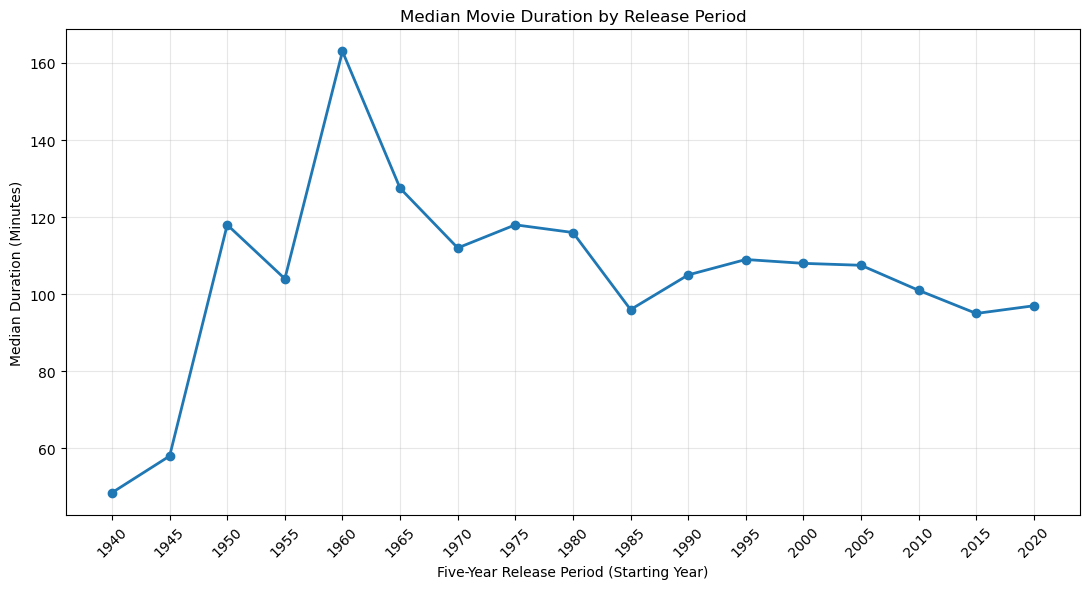

In [33]:


# Median movie duration by release period

plt.figure(figsize=(11, 6))

plt.plot(
    duration_by_period.index,
    duration_by_period["median_duration"],
    marker="o",
    linewidth=2
)

plt.title("Median Movie Duration by Release Period")
plt.xlabel("Five-Year Release Period (Starting Year)")
plt.ylabel("Median Duration (Minutes)")
plt.xticks(duration_by_period.index, rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "median_movie_duration_by_period.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [34]:


# Task 3.18: Verify saved EDA charts

from pathlib import Path

chart_files = [
    "content_distribution.svg",
    "titles_added_by_year.svg",
    "titles_by_release_year.svg",
    "content_rating_distribution.svg",
    "top_15_netflix_genres.svg",
    "movie_duration_distribution.svg",
    "tv_show_season_distribution.svg",
    "top_15_countries.svg",
    "country_movie_tv_comparison.svg",
    "release_year_movie_tv_trend.svg",
    "top_15_directors.svg",
    "top_15_performers.svg",
    "ratings_by_content_type.svg",
    "monthly_content_additions.svg",
    "median_movie_duration_by_period.svg",
]

for filename in chart_files:
    path = Path(filename)
    status = "FOUND" if path.is_file() else "MISSING"
    print(f"{status}: {filename}")

found_count = sum(Path(name).is_file() for name in chart_files)

print(f"\nCharts found: {found_count}/{len(chart_files)}")


FOUND: content_distribution.svg
FOUND: titles_added_by_year.svg
FOUND: titles_by_release_year.svg
FOUND: content_rating_distribution.svg
FOUND: top_15_netflix_genres.svg
FOUND: movie_duration_distribution.svg
FOUND: tv_show_season_distribution.svg
FOUND: top_15_countries.svg
FOUND: country_movie_tv_comparison.svg
FOUND: release_year_movie_tv_trend.svg
FOUND: top_15_directors.svg
FOUND: top_15_performers.svg
FOUND: ratings_by_content_type.svg
FOUND: monthly_content_additions.svg
FOUND: median_movie_duration_by_period.svg

Charts found: 15/15


Statistical Analysis: Movie Duration by Release Period

In [35]:


import pandas as pd
import numpy as np

# Select movies with valid duration and release year
movies = df[
    (df["type"] == "Movie") &
    (df["duration_minutes"].notna()) &
    (df["release_year"].notna())
].copy()

# Define the release periods
conditions = [
    movies["release_year"].between(2005, 2009),
    movies["release_year"].between(2010, 2014),
    movies["release_year"].between(2015, 2019),
    movies["release_year"].between(2020, 2021)
]

labels = ["2005-2009", "2010-2014", "2015-2019", "2020-2021"]

movies["release_period"] = np.select(
    conditions,
    labels,
    default="Other"
)

# Keep only the four periods being compared
period_movies = movies[
    movies["release_period"].isin(labels)
].copy()

# Summarize each group
summary = (
    period_movies
    .groupby("release_period", observed=True)["duration_minutes"]
    .agg(
        sample_size="count",
        mean="mean",
        median="median",
        standard_deviation="std",
        minimum="min",
        maximum="max"
    )
    .reindex(labels)
    .round(2)
)

display(summary)
print("Total movies in the four periods:", len(period_movies))
print("Missing durations:", period_movies["duration_minutes"].isna().sum())


,sample_size,mean,median,standard_deviation,minimum,maximum
release_period,,,,,,
2005-2009,454,110.44,107.5,26.16,25.0,214.0
2010-2014,961,100.88,101.0,26.84,3.0,190.0
2015-2019,3223,95.72,95.0,25.50,10.0,312.0
2020-2021,794,93.64,97.0,29.86,5.0,273.0


Total movies in the four periods: 5432
Missing durations: 0


,count,median,skewness
release_period,,,
2005-2009,454,107.5,0.40
2010-2014,961,101.0,-0.27
2015-2019,3223,95.0,0.07
2020-2021,794,97.0,-0.33


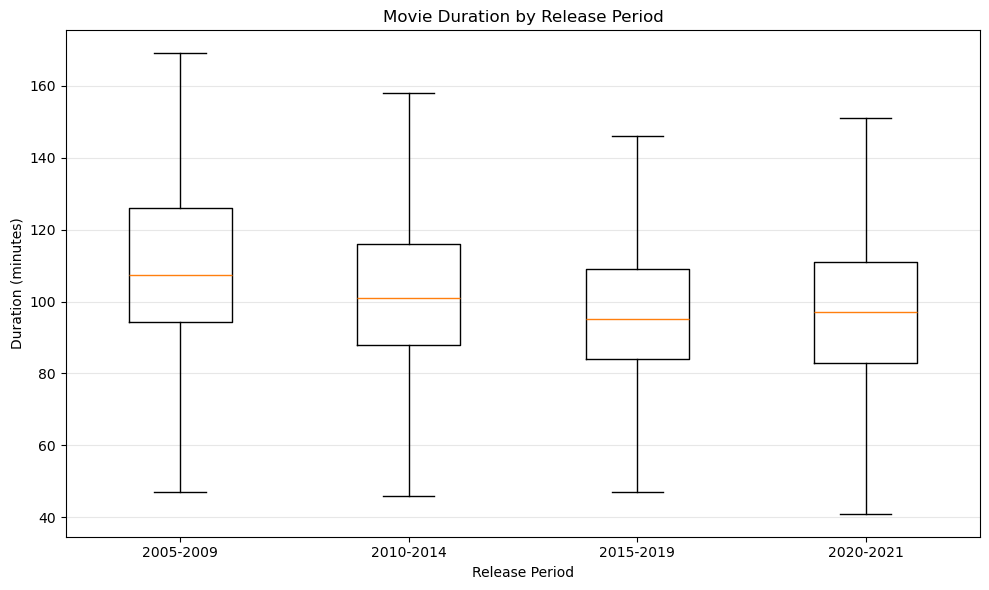

In [36]:


import matplotlib.pyplot as plt
from scipy.stats import skew

# Summarize the distribution of movie durations in each period
distribution_summary = (
    period_movies
    .groupby("release_period")["duration_minutes"]
    .agg(
        count="count",
        median="median",
        skewness=skew
    )
    .reindex(labels)
    .round(2)
)

display(distribution_summary)

# Compare duration distributions using a box plot
plt.figure(figsize=(10, 6))

period_data = [
    period_movies.loc[
        period_movies["release_period"] == period,
        "duration_minutes"
    ]
    for period in labels
]

plt.boxplot(period_data, tick_labels=labels, showfliers=False)
plt.title("Movie Duration by Release Period")
plt.xlabel("Release Period")
plt.ylabel("Duration (minutes)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [37]:


from scipy.stats import kruskal

# Collect movie durations for each release period
groups = [
    period_movies.loc[
        period_movies["release_period"] == period,
        "duration_minutes"
    ].dropna()
    for period in labels
]

# Run the Kruskal-Wallis test
statistic, p_value = kruskal(*groups)

print(f"Kruskal-Wallis statistic: {statistic:.4f}")
print(f"P-value: {p_value:.10g}")

alpha = 0.05

if p_value < alpha:
    print("Result: Statistically significant difference between at least two periods.")
else:
    print("Result: No statistically significant difference detected.")

print(f"Significance level (alpha): {alpha}")


Kruskal-Wallis statistic: 149.5883
P-value: 3.232775206e-32
Result: Statistically significant difference between at least two periods.
Significance level (alpha): 0.05


In [38]:


from itertools import combinations
from scipy.stats import mannwhitneyu

results = []

for period_a, period_b in combinations(labels, 2):
    a = period_movies.loc[
        period_movies["release_period"] == period_a,
        "duration_minutes"
    ].dropna()

    b = period_movies.loc[
        period_movies["release_period"] == period_b,
        "duration_minutes"
    ].dropna()

    test = mannwhitneyu(a, b, alternative="two-sided")

    median_a = a.median()
    median_b = b.median()
    raw_p = test.pvalue

    results.append({
        "period_1": period_a,
        "period_2": period_b,
        "median_1": median_a,
        "median_2": median_b,
        "median_difference_minutes": median_b - median_a,
        "raw_p_value": raw_p
    })

pairwise = pd.DataFrame(results)

# Correct for six pairwise comparisons
pairwise["adjusted_p_value"] = (
    pairwise["raw_p_value"] * len(pairwise)
).clip(upper=1.0)

pairwise["significant_at_0.05"] = (
    pairwise["adjusted_p_value"] < 0.05
)

display(pairwise.round(6))


,period_1,period_2,median_1,median_2,median_difference_minutes,raw_p_value,adjusted_p_value,significant_at_0.05
0,2005-2009,2010-2014,107.5,101.0,-6.5,0.000000,0.00000,True
1,2005-2009,2015-2019,107.5,95.0,-12.5,0.000000,0.00000,True
2,2005-2009,2020-2021,107.5,97.0,-10.5,0.000000,0.00000,True
3,2010-2014,2015-2019,101.0,95.0,-6.0,0.000000,0.00000,True
4,2010-2014,2020-2021,101.0,97.0,-4.0,0.000003,0.00002,True
5,2015-2019,2020-2021,95.0,97.0,2.0,0.910906,1.00000,False


### Statistical Analysis: Movie Duration by Release Period

**Objective:** To investigate whether movie durations differ across four release periods: 2005–2009, 2010–2014, 2015–2019, and 2020–2021.

**Methodology:** The analysis included 5,432 movies with valid duration data. A Kruskal–Wallis test was used to compare the four independent groups. Pairwise Mann–Whitney U tests with Bonferroni correction were used to identify differences between individual periods. Statistical significance was evaluated at α = 0.05.

**Key findings:**
- Median movie duration declined from 107.5 minutes in 2005–2009 to 95 minutes in 2015–2019.
- The Kruskal–Wallis test indicated a statistically significant difference among the release-period distributions (H = 149.5883, p ≈ 3.23 × 10⁻³²).
- Five of the six pairwise comparisons were statistically significant after Bonferroni correction.
- The difference between 2015–2019 and 2020–2021 was not statistically significant after correction (adjusted p = 0.910906).

**Conclusion:** Movie durations in this Netflix catalog dataset varied significantly across most of the periods examined. The median duration decreased over the earlier periods, then increased slightly in 2020–2021; that final increase was not statistically significant compared with 2015–2019.

**Limitations:** These findings describe the available Netflix catalog snapshot and do not establish that movie durations changed across the entire film industry or that release period caused the observed differences.